# 07 Robustness checks

## Loading libraries and data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

os.makedirs("results/figures", exist_ok=True)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "figure.dpi": 110, "savefig.dpi": 200})

CONTROLS = "C(rating) + log_popularity + log_age + verified"
Q3_CONTROLS = CONTROLS + " + log_position + log_length"
CLEAN = {"reasons_pct": "Reasons", "mentions_pct": "Mentions of others", "certainty": "Certainty",
         "negation_pct": "Negation", "i_pct": "First-person I",
         "pos_emotion_clean_pct": "Positive emotion", "neg_emotion_clean_pct": "Negative emotion",
         "anger_clean_pct": "Anger", "sadness_clean_pct": "Sadness", "money_clean_pct": "Money"}
ORIGINAL = {("pos_emotion_pct" if k == "pos_emotion_clean_pct" else k.replace("_clean_pct", "_pct")): v
            for k, v in CLEAN.items()}

def add_columns(d):
    d = d.copy()
    d["log_popularity"] = np.log(d["product_n_reviews"])
    d["log_age"] = np.log1p(d["age_days"])
    d["verified"] = d["verified_purchase"].astype(int)
    d["log_length"] = np.log(d["n_words"].clip(lower=1))
    d["log_position"] = np.log1p(d["n_prior"])
    return d

def make_groups(d, average="prior_mean", min_prior=5):
    d = d[d["n_prior"] >= min_prior]
    c = d[average]
    low = d[(d["rating"] <= 2) & ((c >= 4) | (c <= 2.5))].copy()
    low["disagree"] = (low[average] >= 4).astype(int)
    return {"Low stars (1-2)": low}

def cluster(d):
    return {"groups": pd.factorize(d["parent_asin"])[0]}

def pooled_sd(a, b):
    na, nb = len(a), len(b)
    return np.sqrt(((na - 1) * a.var() + (nb - 1) * b.var()) / (na + nb - 2))

def run_q1(groups, features, spec):
    rows = []
    for comp, d in groups.items():
        for col, name in features.items():
            s = d.dropna(subset=[col])
            m = smf.ols(f"{col} ~ disagree + {CONTROLS}", data=s).fit(cov_type="cluster", cov_kwds=cluster(s))
            sd = pooled_sd(s.loc[s["disagree"] == 1, col], s.loc[s["disagree"] == 0, col])
            rows.append({"check": spec, "comparison": comp, "feature": name, "n": len(s),
                         "n_disagree": int(s["disagree"].sum()), "difference": m.params["disagree"],
                         "d": m.params["disagree"] / sd, "p": m.pvalues["disagree"]})
    out = pd.DataFrame(rows)
    out["p_holm"] = multipletests(out["p"], method="holm")[1]
    out["significant"] = out["p_holm"] < 0.05
    return out

feat = add_columns(pd.read_parquet("data/processed/features.parquet"))
allrev = pd.read_parquet("data/processed/reviews_clean.parquet")
allrev = add_columns(allrev[allrev["prior_mean"].notna()])
print("25+ word reviews:", len(feat), "| all reviews with 5+ earlier reviews:", len(allrev))

25+ word reviews: 169384 | all reviews with 5+ earlier reviews: 410866


## Writing features under each check

In [2]:
CHECKS = {
    "Main (as in 05)":       (make_groups(feat), CLEAN),
    "Original NRC lists":    (make_groups(feat), ORIGINAL),
    "Minimum 10 earlier reviews":      (make_groups(feat, min_prior=10), CLEAN),
    "Minimum 20 earlier reviews":      (make_groups(feat, min_prior=20), CLEAN),
    "Average of last 10 reviews":         (make_groups(feat, average="prior_mean_last10", min_prior=10), CLEAN),
    "Length 50+ words":      (make_groups(feat[feat["n_words"] >= 50]), CLEAN),
}
sizes = pd.DataFrame([{"check": k, "comparison": c, "disagree": int(d["disagree"].sum()),
                       "agree": int((d["disagree"] == 0).sum())}
                      for k, (g, _) in CHECKS.items() for c, d in g.items()])
print(sizes.to_string(index=False), "\n")

q1_all = pd.concat([run_q1(g, f, k) for k, (g, f) in CHECKS.items()], ignore_index=True)
q1_all.to_csv("results/robustness_q1_all_checks.csv", index=False)
print("Done:", q1_all["check"].nunique(), "checks x", len(q1_all) // q1_all["check"].nunique(), "tests")

                     check      comparison  disagree  agree
           Main (as in 05) Low stars (1-2)     16816   2881
        Original NRC lists Low stars (1-2)     16816   2881
Minimum 10 earlier reviews Low stars (1-2)     13187   1868
Minimum 20 earlier reviews Low stars (1-2)      9835   1076
Average of last 10 reviews Low stars (1-2)     11535   3652
          Length 50+ words Low stars (1-2)      7364    997 

Done: 6 checks x 10 tests


## Summary of checks

In [3]:
main = q1_all[q1_all["check"] == "Main (as in 05)"].set_index(["comparison", "feature"])
alts = [c for c in CHECKS if c != "Main (as in 05)"]

table = q1_all.assign(cell=lambda x: x["d"].round(3).astype(str) + np.where(x["significant"], "*", ""))
table = table.pivot_table(index=["comparison", "feature"], columns="check", values="cell", aggfunc="first")
table = table[list(CHECKS)]

def survives(row):
    m = main.loc[row.name]
    if not m["significant"]:
        return "main not significant"
    alt = q1_all[(q1_all["comparison"] == row.name[0]) & (q1_all["feature"] == row.name[1]) &
                 (q1_all["check"] != "Main (as in 05)")]
    ok = (alt["significant"] & (np.sign(alt["d"]) == np.sign(m["d"]))).sum()
    return f"{ok} of {len(alt)}"

table["survives"] = table.apply(survives, axis=1)
order = list(CLEAN.values())
table = table.reindex([(c, f) for c in ["Low stars (1-2)"] for f in order])
table.to_csv("results/robustness_q1_summary.csv")
pd.set_option("display.width", 250)
print(table.to_string())

check                              Main (as in 05) Original NRC lists Minimum 10 earlier reviews Minimum 20 earlier reviews Average of last 10 reviews Length 50+ words              survives
comparison      feature                                                                                                                                                                      
Low stars (1-2) Reasons                       0.03               0.03                      0.025                      0.026                      0.031            0.006  main not significant
                Mentions of others          -0.019             -0.019                       -0.0                      0.054                      0.014            0.009  main not significant
                Certainty                   -0.008             -0.008                     -0.015                     -0.066                     -0.031            0.001  main not significant
                Negation                    -0.24*

## Effect size plot

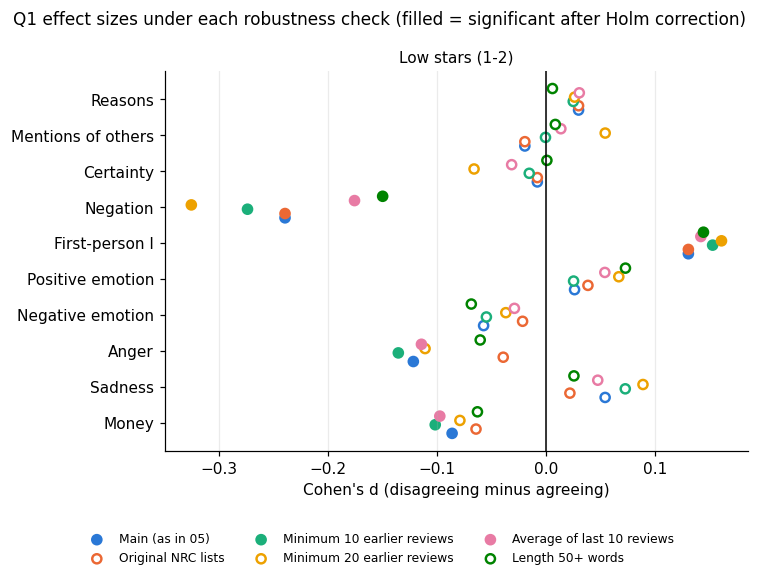

In [4]:
CHECK_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
fig, ax = plt.subplots(figsize=(7, 5.2))
names = order[::-1]
offsets = np.linspace(-0.3, 0.3, len(CHECKS))
for comp in ["Low stars (1-2)"]:
    for (check, colour, off) in zip(CHECKS, CHECK_COLOURS, offsets):
        t = q1_all[(q1_all["check"] == check) & (q1_all["comparison"] == comp)].set_index("feature").loc[names]
        y = np.arange(len(names)) + off
        ax.scatter(t["d"], y, s=36, color=colour, label=check,
                   facecolors=np.where(t["significant"], colour, "white"), linewidths=1.6)
    ax.axvline(0, color="black", linewidth=1)
    ax.set_yticks(np.arange(len(names)), names)
    ax.set_title(comp, fontsize=10)
    ax.set_xlabel("Cohen's d (disagreeing minus agreeing)")
    ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle("Q1 effect sizes under each robustness check (filled = significant after Holm correction)", fontsize=11)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig("results/figures/fig_robustness_q1.png")
plt.show()

## Helpful votes under each check

In [5]:
Q3_CHECKS = {"Main (as in 05)": make_groups(allrev),
             "Minimum 10 earlier reviews": make_groups(allrev, min_prior=10),
             "Minimum 20 earlier reviews": make_groups(allrev, min_prior=20),
             "Average of last 10 reviews": make_groups(allrev, average="prior_mean_last10", min_prior=10)}
rows = []
for check, groups in Q3_CHECKS.items():
    for comp, d in groups.items():
        d = d.assign(any_vote=d["any_helpful"].astype(int))
        m1 = smf.logit(f"any_vote ~ disagree + {Q3_CONTROLS}", data=d).fit(disp=0, cov_type="cluster", cov_kwds=cluster(d))
        voted = d[d["helpful_vote"] > 0]
        m2 = smf.negativebinomial(f"helpful_vote ~ disagree + {Q3_CONTROLS}", data=voted).fit(
            disp=0, maxiter=200, cov_type="cluster", cov_kwds=cluster(voted))
        lo1, hi1 = np.exp(m1.conf_int().loc["disagree"])
        lo2, hi2 = np.exp(m2.conf_int().loc["disagree"])
        rows.append({"check": check, "comparison": comp, "n": len(d), "n_disagree": int(d["disagree"].sum()),
                     "odds_ratio_any_vote": np.exp(m1.params["disagree"]), "or_ci_low": lo1, "or_ci_high": hi1,
                     "p_any_vote": m1.pvalues["disagree"],
                     "rate_ratio_votes": np.exp(m2.params["disagree"]), "rr_ci_low": lo2, "rr_ci_high": hi2,
                     "p_votes": m2.pvalues["disagree"], "nb_converged": m2.mle_retvals.get("converged", None)})
q3_rob = pd.DataFrame(rows)
q3_rob.to_csv("results/robustness_q3.csv", index=False)
print(q3_rob.round(4).to_string(index=False))

                     check      comparison     n  n_disagree  odds_ratio_any_vote  or_ci_low  or_ci_high  p_any_vote  rate_ratio_votes  rr_ci_low  rr_ci_high  p_votes  nb_converged
           Main (as in 05) Low stars (1-2) 44113       36247               1.9477     1.6436      2.3081         0.0            1.0690     0.9069      1.2601   0.4267          True
Minimum 10 earlier reviews Low stars (1-2) 33397       28293               2.2273     1.7440      2.8445         0.0            1.1744     0.9370      1.4720   0.1630          True
Minimum 20 earlier reviews Low stars (1-2) 24034       21041               2.4944     1.7081      3.6428         0.0            1.3209     0.9592      1.8191   0.0882          True
Average of last 10 reviews Low stars (1-2) 34405       25010               1.8941     1.6088      2.2300         0.0            1.2527     1.0909      1.4384   0.0014          True
